# 01 - GPyTorch Basic 1D Regression

## Problem setup
We observe noisy measurements of an unknown function.

$$y_i = f(x_i) + \epsilon_i, \quad \epsilon_i \sim \mathcal{N}(0, \sigma_n^2)$$

A Gaussian Process places a probability distribution over possible functions:

$$f(x) \sim \mathcal{GP}(m(x), k(x,x'))$$

where:
- $m(x)$ is the mean function (our baseline expectation)
- $k(x,x')$ is the kernel (how strongly two points are related)

In [1]:
# -----------------------------
# 0) Imports and reproducibility
# -----------------------------

# Standard math constants/functions (for pi, sine-like formulas, etc.)
import math

# Torch handles tensors and optimization
import torch

# GPyTorch provides GP models, kernels, likelihoods, and inference utilities
import gpytorch

# Matplotlib is used for visualizing data, predictions, and uncertainty
import matplotlib.pyplot as plt

# Set a random seed so runs are repeatable (same synthetic noise each run).
torch.manual_seed(7)

# Optional: show library versions so results are easier to reproduce later
print(f"torch version: {torch.__version__}")
print(f"gpytorch version: {gpytorch.__version__}")

torch version: 2.12.0+cpu
gpytorch version: 1.15.2


## 1) Create a 1D Toy Dataset (Noisy Measurements)

We will:
1. Create input locations $x$ on $[0,1]$
2. Define a hidden smooth true function $f(x)$
3. Add Gaussian noise to create observed values $y$

This gives the training set $(X, y)$ that the GP learns from.

In [2]:
# -----------------------------
# 1) Build synthetic training data
# -----------------------------

# Create 30 evenly spaced x-values in [0, 1].
# Shape: [30]
train_x = torch.linspace(0, 1, 30)

# Define the hidden ground-truth function.
# We combine a low-frequency sine with a small higher-frequency cosine term
# so the curve has smooth structure with a little extra variation.
def true_function(x):
    return torch.sin(x * (2 * math.pi)) + 0.2 * torch.cos(x * (6 * math.pi))

# Standard deviation of measurement noise.
# Larger value -> noisier sensor observations.
noise_std = 0.15

# Observed data = true signal + Gaussian noise
# This is exactly: y_i = f(x_i) + epsilon_i, epsilon_i ~ N(0, noise_std^2).
train_y = true_function(train_x) + noise_std * torch.randn_like(train_x)

print(f"Number of training points: {train_x.numel()}")
print(f"Noise std used for synthetic observations: {noise_std}")

Number of training points: 30
Noise std used for synthetic observations: 0.15


## 2) Define the Exact GP Model

Model pieces:
- **Mean function**: Constant baseline value.
- **Kernel (RBF)**: Points close in $x$ should have similar outputs.
- **Likelihood (Gaussian)**: Observations contain noise.

The RBF kernel is:

$$k(x,x') = \sigma_f^2 \exp\left(-\frac{(x-x')^2}{2\ell^2}\right)$$

where:
- $\ell$ (lengthscale) controls how quickly the function can change
- $\sigma_f^2$ (output scale) controls overall vertical variation

In [3]:
# -----------------------------
# 2) Define Exact GP model class
# -----------------------------

class ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        # ExactGP stores training data internally for exact inference.
        super().__init__(train_x, train_y, likelihood)

        # Mean function m(x): here we use a single constant value.
        self.mean_module = gpytorch.means.ConstantMean()

        # Covariance function k(x, x').
# ScaleKernel adds an output variance parameter around the base kernel.
        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.RBFKernel()
        )

    def forward(self, x):
        # Compute mean vector m(x)
        mean_x = self.mean_module(x)

        # Compute covariance matrix K(x, x)
        covar_x = self.covar_module(x)

        # Return multivariate normal distribution over function values f(x).
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

# Likelihood models observation noise p(y | f).
likelihood = gpytorch.likelihoods.GaussianLikelihood()

# Instantiate model with training data + likelihood.
model = ExactGPModel(train_x, train_y, likelihood)

## 3) Train by Maximizing Marginal Log Likelihood (MLL)

> Goal: learn kernel + noise parameters that best explain observed data.

For GP regression, we optimize:

$$\log p(\mathbf{y}\mid X, \theta)$$

where $\theta$ contains hyperparameters (lengthscale, output scale, noise, mean).

In code, we minimize negative MLL:

$$\mathcal{L}(\theta) = -\log p(\mathbf{y}\mid X, \theta)$$

If training goes well, this loss should generally decrease over iterations.

In [4]:
# -----------------------------
# 3) Train the GP hyperparameters
# -----------------------------

# Put model/likelihood into training mode.
model.train()
likelihood.train()

# Adam optimizer updates trainable parameters (mean, kernel, noise).
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

# Exact marginal log likelihood objective.
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

training_iters = 150
loss_history = []

for i in range(training_iters):
    # Clear previous gradients
    optimizer.zero_grad()

    # Forward pass: distribution over f(train_x)
    output = model(train_x)

    # Negative MLL (because optimizers minimize)
    loss = -mll(output, train_y)

    # Backprop gradients through model parameters
    loss.backward()

    # Apply one optimization step
    optimizer.step()

    loss_history.append(loss.item())
    if (i + 1) % 25 == 0:
        print(f"Iter {i+1:>3}/{training_iters} - Loss: {loss.item():.4f}")

# Print learned hyperparameters so you can connect math <-> learned values
lengthscale = model.covar_module.base_kernel.lengthscale.item()
outputscale = model.covar_module.outputscale.item()
noise = likelihood.noise.item()
print(f"Learned lengthscale: {lengthscale:.4f}")
print(f"Learned outputscale: {outputscale:.4f}")
print(f"Learned noise variance: {noise:.4f}")

Iter  25/150 - Loss: 0.2466
Iter  50/150 - Loss: 0.0992
Iter  75/150 - Loss: 0.0870
Iter 100/150 - Loss: 0.0860
Iter 125/150 - Loss: 0.0859
Iter 150/150 - Loss: 0.0859
Learned lengthscale: 0.1349
Learned outputscale: 0.3614
Learned noise variance: 0.0271


## 4) Predict Posterior Mean and Uncertainty

> After training, GP gives a full predictive distribution at each test point.

For each $x_*$, the model returns:
- Posterior mean $\mu(x_*)$ (best estimate)
- Posterior variance $\sigma^2(x_*)$ (uncertainty)

A common confidence interval is approximately:

$$\mu(x_*) \pm 2\sigma(x_*)$$

The interval is usually narrower near many observations and wider in sparse regions.

In [6]:
# -----------------------------
# 4) Inference on a dense test grid
# -----------------------------

# Switch model/likelihood to evaluation mode (important for correct inference behavior).
model.eval()
likelihood.eval()

# Dense x-grid for smooth plotting of posterior mean/uncertainty.
test_x = torch.linspace(0, 1, 300)

# torch.no_grad(): no gradient tracking during inference (faster, less memory).
# fast_pred_var(): GPyTorch setting for efficient predictive variances.
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    # Predictive distribution over observed outputs y* (includes observation noise).
    pred_dist = likelihood(model(test_x))

    # Mean prediction mu(x)
    pred_mean = pred_dist.mean

    # Lower/upper confidence bounds (roughly mu +/- 2 sigma).
    lower, upper = pred_dist.confidence_region()

## 5) Visualize and Interpret Results

How to read it:
- Black dots: noisy observed measurements
- Dashed line: hidden true function (only available because this is synthetic data)
- Solid line: GP predictive mean
- Shaded band: uncertainty interval

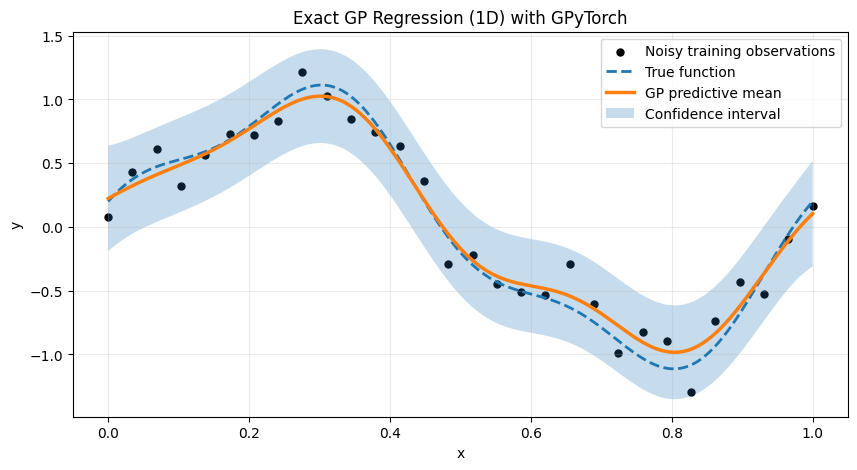

In [7]:
# -----------------------------
# 5) Plot predictions + uncertainty
# -----------------------------

# Compute the true function on test grid (for visual comparison only).
true_y_test = true_function(test_x)

plt.figure(figsize=(10, 5))

# Training observations (noisy measurements)
plt.scatter(
    train_x.numpy(),
    train_y.numpy(),
    color="black",
    s=25,
    label="Noisy training observations"
 )

# True latent function (available only in simulation)
plt.plot(
    test_x.numpy(),
    true_y_test.numpy(),
    linestyle="--",
    linewidth=2,
    label="True function"
 )

# GP posterior mean
plt.plot(
    test_x.numpy(),
    pred_mean.numpy(),
    linewidth=2.5,
    label="GP predictive mean"
 )

# GP uncertainty band (confidence region)
plt.fill_between(
    test_x.numpy(),
    lower.numpy(),
    upper.numpy(),
    alpha=0.25,
    label="Confidence interval"
 )

plt.title("Exact GP Regression (1D) with GPyTorch")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

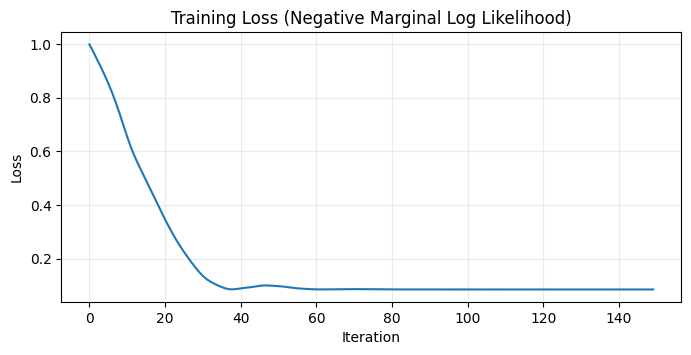

In [8]:
# -----------------------------
# 6) Plot training objective history
# -----------------------------

# A decreasing curve indicates optimization is generally improving fit quality.
plt.figure(figsize=(8, 3.5))
plt.plot(loss_history)
plt.title("Training Loss (Negative Marginal Log Likelihood)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(alpha=0.25)
plt.show()